# Data Visualization - Superstore Sales Performance & Profitability Analysis:
This project focuses on converting raw transactional sales data into decision-enabling visual representations, including trend tracking, categorical comparisons, correlation studies, and an executive dashboard layout.

### Core Business Questions Addressed:
1. **Revenue & Profit Dynamics:** How do monthly sales and net profits evolve across the 2022–2023 operating period?
2. **Product Sub-Category Profitability:** Which merchandise lines drive volume versus which ones generate operating losses?
3. **Discount vs. Profit Relationship:** At what discount rate does profitability turn negative?
4. **Regional & Category Contribution:** How does category performance differ across the West, East, Central, and South regions?
5. **Customer Segment Mix:** What is the proportional revenue contribution between Consumer, Corporate, and Home Office clients?
6. **Logistics & Fulfillment Margin:** Which shipping mode delivers the strongest net operating margin percentage?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
# formatting 
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

# Load Dataset
df = pd.read_csv('Superstore_Sales.csv')

# Convert dates to datetime objects
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'])

# Create helper time dimensions
df['Year_Month'] = df['Order_Date'].dt.to_period('M')
df['Profit_Margin_%'] = (df['Profit'] / df['Sales']) * 100

print("Dataset ready:", df.shape)

Dataset ready: (100000, 17)


## Executive KPI Scorecard

In [2]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
overall_margin = (total_profit / total_sales) * 100
total_orders = df['Order_ID'].nunique()
avg_discount = df['Discount'].mean() * 100

print(f"Total Revenue:       ${total_sales:,.2f}")
print(f"Total Net Profit:    ${total_profit:,.2f}")
print(f"Overall Margin:      {overall_margin:.2f}%")
print(f"Total Unique Orders: {total_orders:,}")
print(f"Average Discount:    {avg_discount:.2f}%")

Total Revenue:       $46,834,142.56
Total Net Profit:    $8,695,590.81
Overall Margin:      18.57%
Total Unique Orders: 100,000
Average Discount:    12.32%


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Order_ID         100000 non-null  str           
 1   Order_Date       100000 non-null  datetime64[us]
 2   Ship_Date        100000 non-null  datetime64[us]
 3   Ship_Mode        100000 non-null  str           
 4   Customer_Name    100000 non-null  str           
 5   Segment          100000 non-null  str           
 6   Region           100000 non-null  str           
 7   State            100000 non-null  str           
 8   City             100000 non-null  str           
 9   Category         100000 non-null  str           
 10  Sub_Category     100000 non-null  str           
 11  Sales            100000 non-null  float64       
 12  Quantity         100000 non-null  int64         
 13  Discount         100000 non-null  float64       
 14  Profit           100000 non-null

## EDA

### Monthly Revenue & Profit Trajectory (2022–2023)

**Objective & Business Context:**
Tracks high-level business velocity by comparing monthly gross revenue ($Sales) against net earnings ($Profit) across the operational period. 

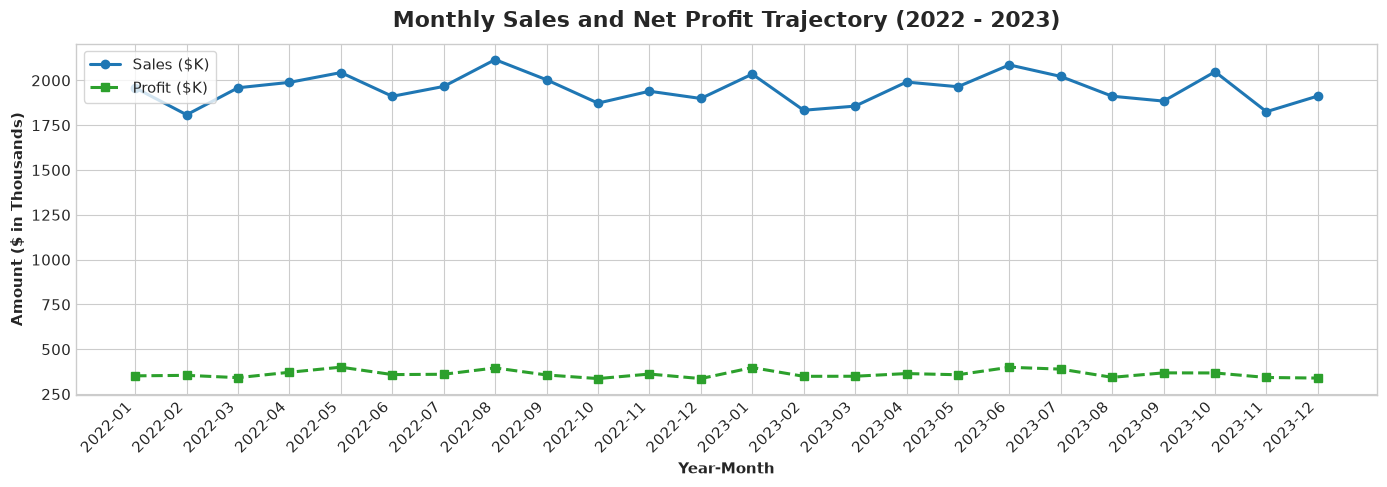

In [4]:
# 1. Clean and convert columns in original dataframe
for col in ['Sales', 'Profit']:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# 2. Group and aggregate
monthly_data = df.groupby('Year_Month').agg({'Sales': 'sum', 'Profit': 'sum'}).reset_index()
monthly_data = monthly_data.sort_values('Year_Month')

# 3. Explicitly ensure both columns are float before plotting
sales_vals = monthly_data['Sales'].astype(float) / 1000
profit_vals = monthly_data['Profit'].astype(float) / 1000
x_vals = monthly_data['Year_Month'].astype(str)

# 4. Plot
plt.figure(figsize=(14, 5))
plt.plot(x_vals, sales_vals, marker='o', color='#1f77b4', linewidth=2.2, label='Sales ($K)')
plt.plot(x_vals, profit_vals, marker='s', color='#2ca02c', linewidth=2.2, linestyle='--', label='Profit ($K)')
plt.title('Monthly Sales and Net Profit Trajectory (2022 - 2023)', fontsize=16, fontweight='bold', pad=12)
plt.xlabel('Year-Month', fontweight='bold')
plt.ylabel('Amount ($ in Thousands)', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

### Product Sub-Category Sales vs. Profitability

**Objective & Business Context:**
A dual-metric horizontal comparison designed to isolate top-tier revenue drivers from products that consume working capital without delivering proportional operating profit.

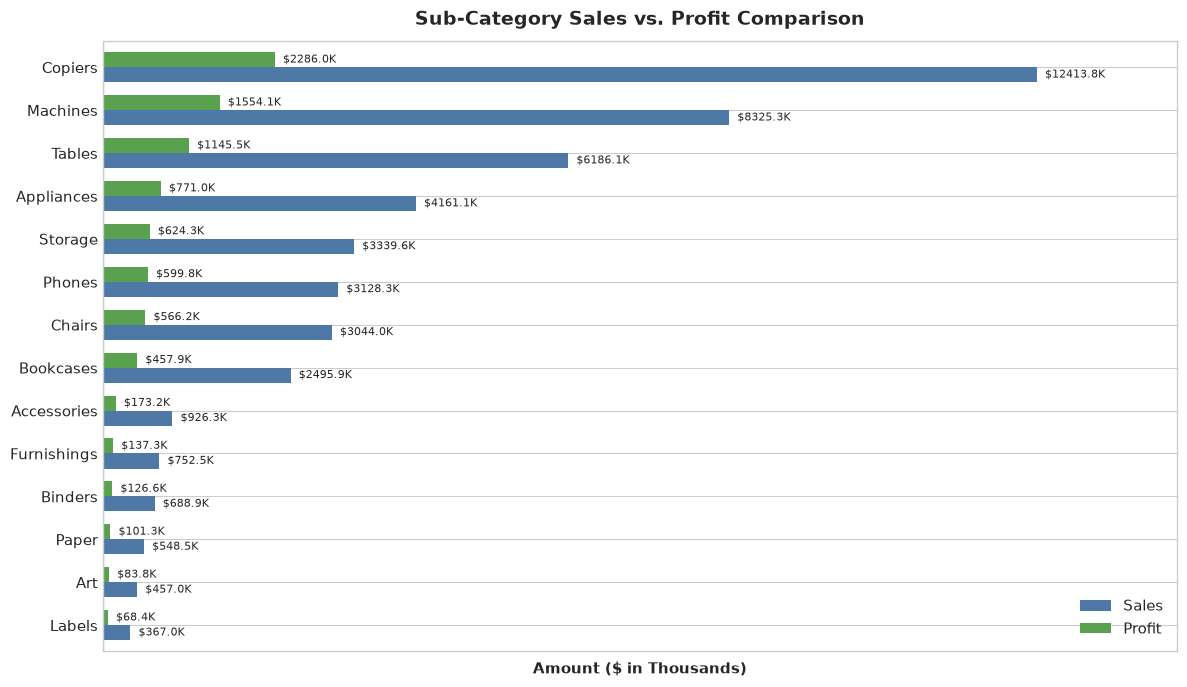

In [11]:
subcat = df.groupby('Sub_Category')[['Sales', 'Profit']].sum() / 1e3
subcat = subcat.sort_values(by='Sales', ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))
subcat.plot(kind='barh', ax=ax, color=['#4e79a7', '#59a14f'], width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt=' $%.1fK', fontsize=8, padding=3)
ax.set_title('Sub-Category Sales vs. Profit Comparison', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Amount ($ in Thousands)', fontweight='bold')
ax.set_ylabel('')
ax.set_xlim(right=subcat['Sales'].max() * 1.15)
ax.axvline('')
plt.tight_layout()
plt.show()

### Discount Sensitivity & Break-Even Margin Analysis

**Objective & Business Context:**
A regression scatter plot mapping individual order discounts against resulting net profit to evaluate promotional elasticity and detect margin risk thresholds.

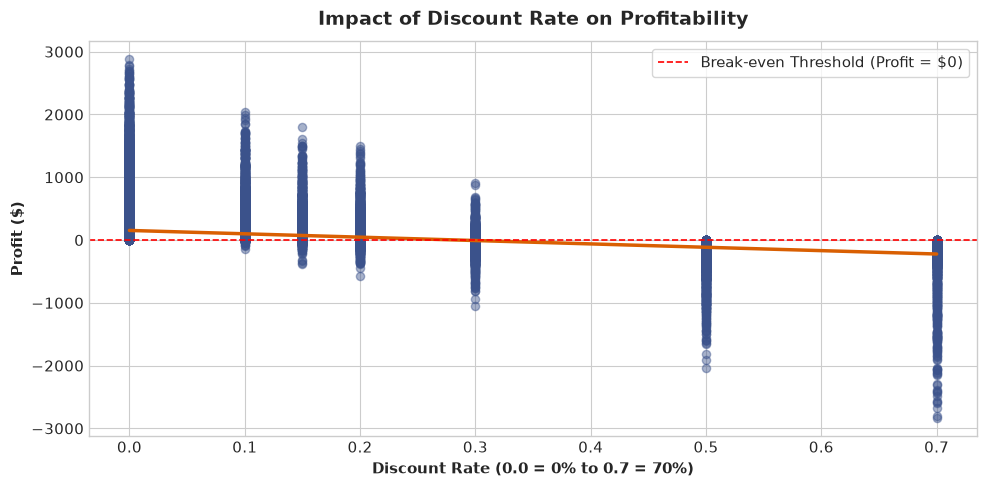

In [6]:
plt.figure(figsize=(10, 5))
ax = sns.regplot(x='Discount', y='Profit', data=df,
                 scatter_kws={'alpha': 0.45, 'color': '#3b528b', 's': 35},
                 line_kws={'color': '#d95f02', 'linewidth': 2.5})

plt.axhline(0, color='red', linestyle='--', linewidth=1.2, label='Break-even Threshold (Profit = $0)')
plt.title('Impact of Discount Rate on Profitability', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Discount Rate (0.0 = 0% to 0.7 = 70%)', fontweight='bold')
plt.ylabel('Profit ($)', fontweight='bold')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### Geographic & Category Revenue Distribution

**Objective & Business Context:**
Evaluates how regional customer preferences across the **West**, **East**, **Central**, and **South** influence product category adoption across Technology, Furniture, and Office Supplies.

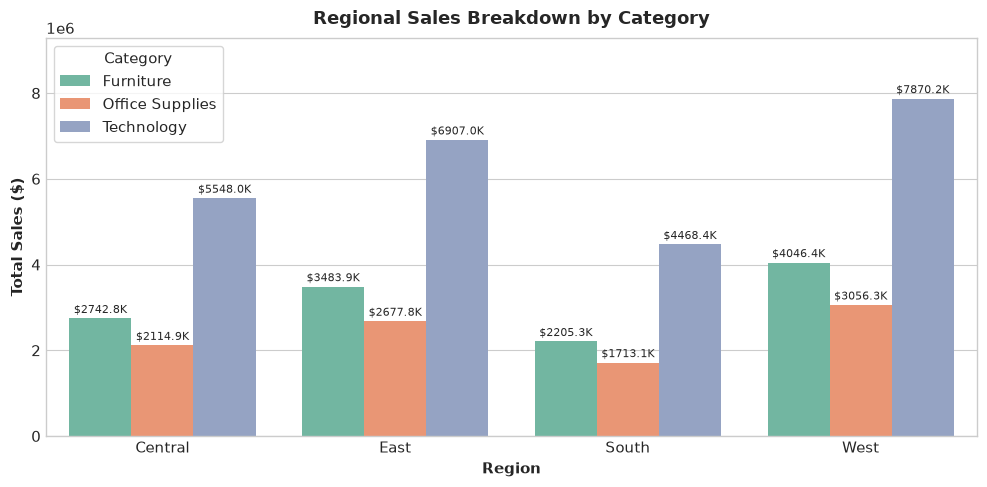

In [7]:
plt.figure(figsize=(10, 5))
reg_cat = df.groupby(['Region', 'Category'])['Sales'].sum().reset_index()
ax=sns.barplot(x='Region', y='Sales', hue='Category', data=reg_cat, palette='Set2')
plt.title('Regional Sales Breakdown by Category', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Region', fontweight='bold')
plt.ylabel('Total Sales ($)', fontweight='bold')
for c in ax.containers:
    ax.bar_label(c, labels=[f'${v/1e3:.1f}K' for v in c.datavalues], fontsize=8, padding=2)
plt.ylim(0, reg_cat['Sales'].max() * 1.18)
plt.legend(title='Category', frameon=True)
plt.tight_layout()
plt.show()

### Customer Segment Contribution 

**Objective & Business Context:**
Breaks down the company's total revenue contribution across the three primary target audiences: Consumer, Corporate, and Home Office clients.

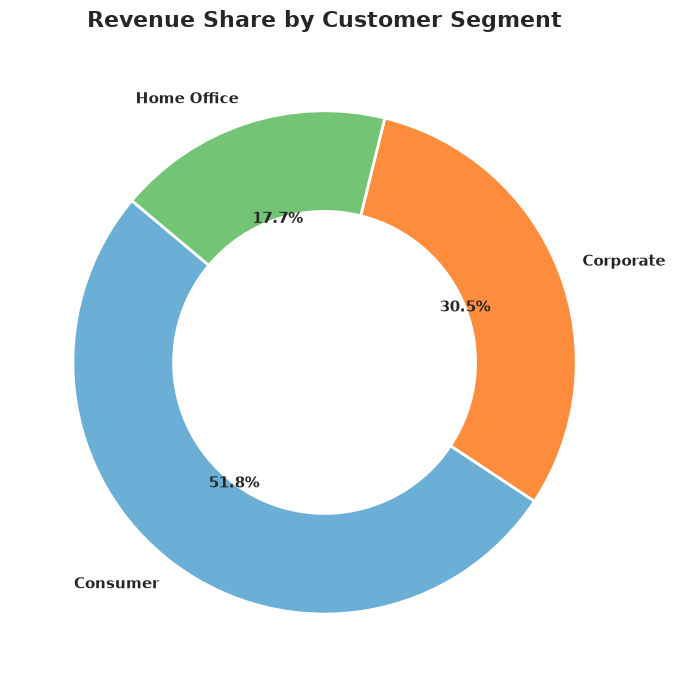

In [8]:
segment_sales = df.groupby('Segment')['Sales'].sum()
plt.figure(figsize=(7, 7))
wedges, texts, autotexts = plt.pie(
    segment_sales, 
    labels=segment_sales.index, 
    autopct='%1.1f%%',
    startangle=140, 
    colors=['#6baed6', '#fd8d3c', '#74c476'],
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontweight': 'bold', 'fontsize': 11}
)
plt.title('Revenue Share by Customer Segment', fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Logistics Fulfillment & Shipping Mode Margin Performance

**Objective & Business Context:**
Measures the operating margin percentage generated across the four available fulfillment options to evaluate carrier efficiency and logistics profitability.

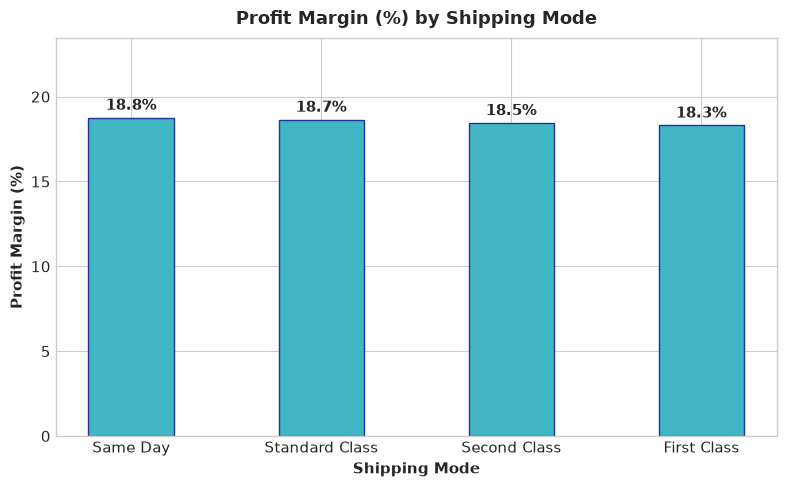

In [9]:
ship_perf = df.groupby('Ship_Mode').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()
fig, ax = plt.subplots(figsize=(8, 5))
ship_perf['Profit_Margin_%'] = (ship_perf['Total_Profit'] / ship_perf['Total_Sales']) * 100
ship_perf = ship_perf.sort_values('Profit_Margin_%', ascending=False)
bars =ax.bar(ship_perf['Ship_Mode'], ship_perf['Profit_Margin_%'], color='#41b6c4', edgecolor='#253494', width=0.45)
plt.title('Profit Margin (%) by Shipping Mode', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Shipping Mode', fontweight='bold')
plt.ylabel('Profit Margin (%)', fontweight='bold')
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontweight='bold')
plt.ylim(0, ship_perf['Profit_Margin_%'].max() * 1.25)
plt.tight_layout()
plt.show()

## Single-Page Executive Dashboard
Combines all operational views—time series, product performance, discount sensitivity, regional share, segment mix, and logistics efficiency—into a single publication-ready visualization layout.

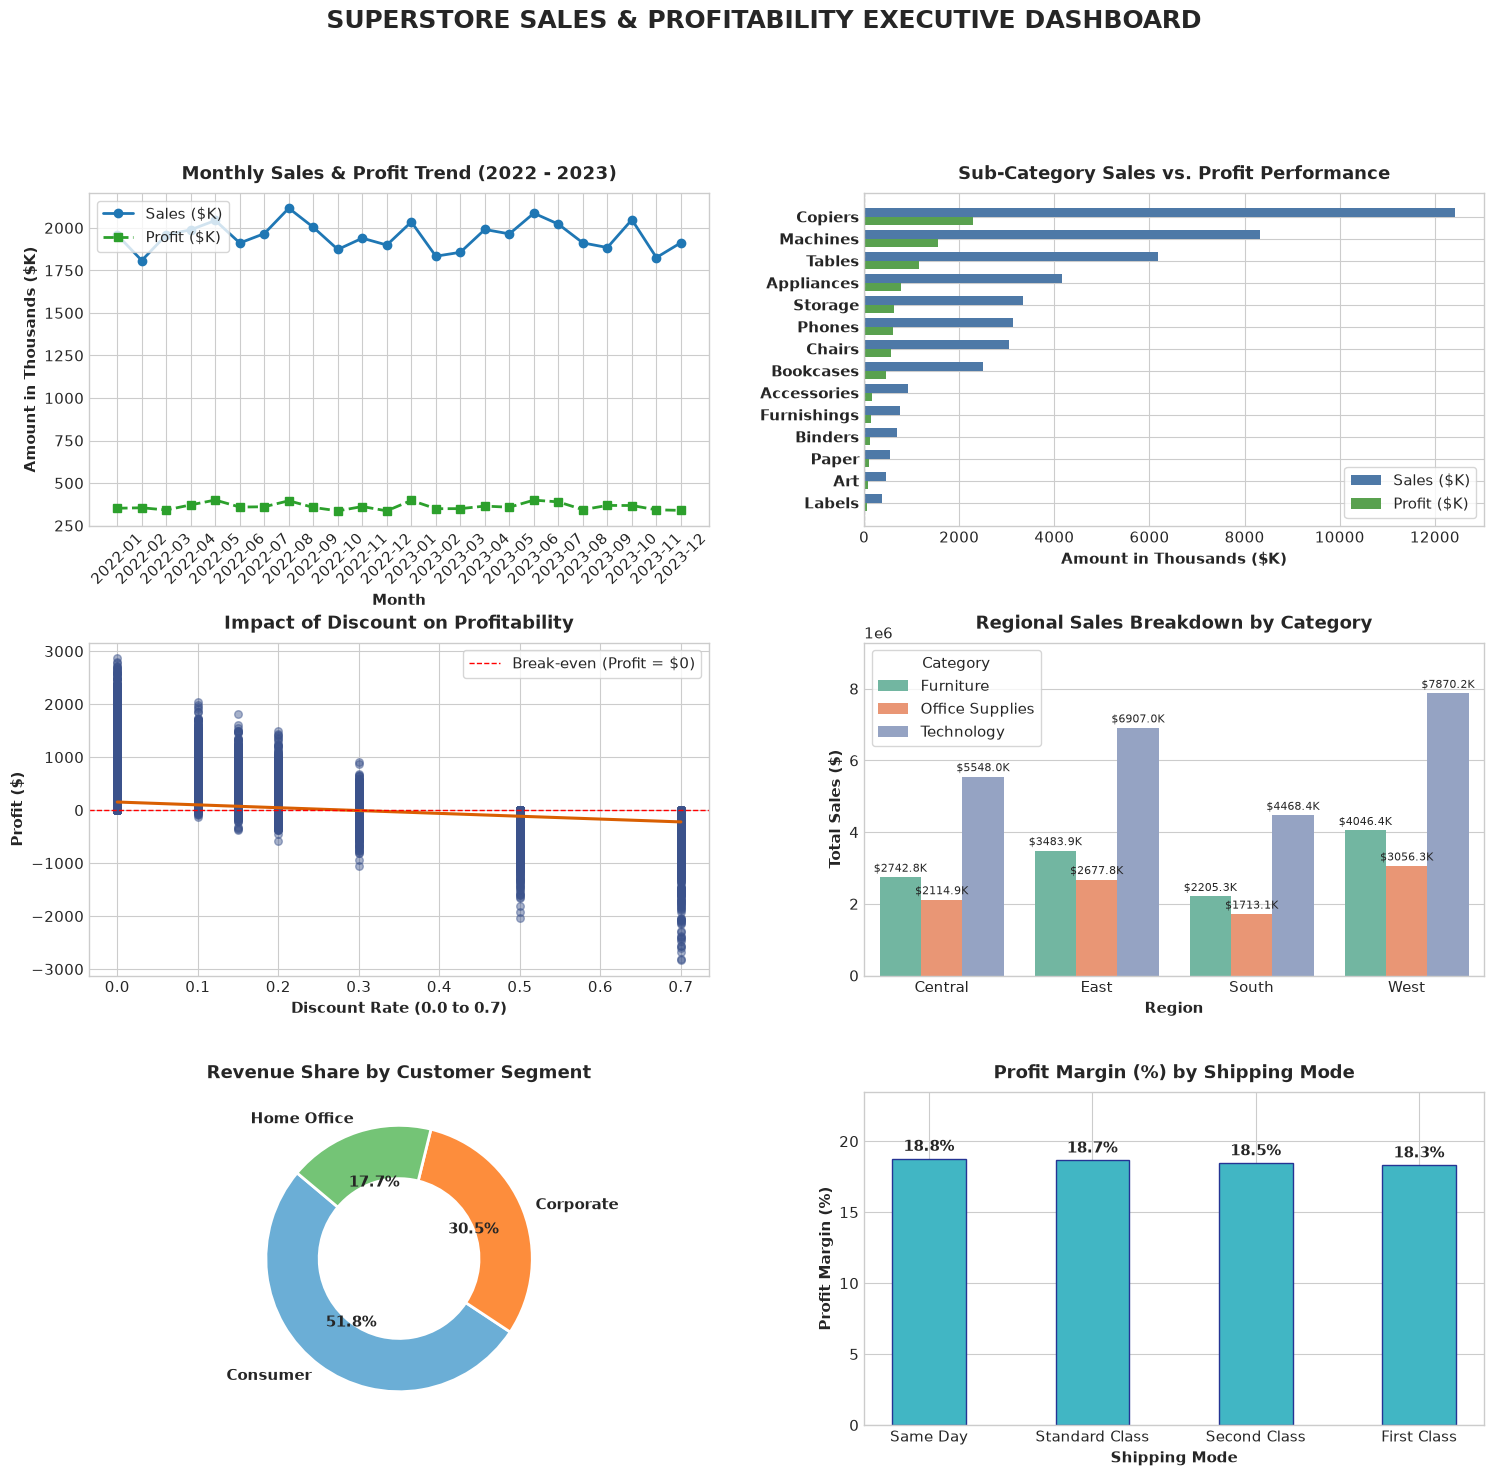

In [10]:
# Create 3x2 Dashboard Canvas
fig, axes = plt.subplots(3, 2, figsize=(18, 16))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. Monthly Trajectory
df['Year_Month'] = df['Order_Date'].dt.to_period('M').astype(str)
monthly = df.groupby('Year_Month').agg({'Sales': 'sum', 'Profit': 'sum'}).reset_index().sort_values('Year_Month')
ax1 = axes[0, 0]
ax1.plot(monthly['Year_Month'], monthly['Sales'] / 1e3, marker='o', color='#1f77b4', linewidth=2, label='Sales ($K)')
ax1.plot(monthly['Year_Month'], monthly['Profit'] / 1e3, marker='s', color='#2ca02c', linewidth=2, linestyle='--', label='Profit ($K)')
ax1.set_title('Monthly Sales & Profit Trend (2022 - 2023)', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Month', fontweight='bold')
ax1.set_ylabel('Amount in Thousands ($K)', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax1.legend(loc='upper left', frameon=True)

# 2. Sub-Category Sales vs Profit
subcat = df.groupby('Sub_Category').agg({'Sales': 'sum', 'Profit': 'sum'}).reset_index().sort_values('Sales', ascending=True)
ax2 = axes[0, 1]
y_idx = np.arange(len(subcat))
ax2.barh(y_idx + 0.19, subcat['Sales'] / 1e3, height=0.38, label='Sales ($K)', color='#4e79a7')
ax2.barh(y_idx - 0.19, subcat['Profit'] / 1e3, height=0.38, label='Profit ($K)', 
         color=['#59a14f' if p >= 0 else '#e15759' for p in subcat['Profit']])
ax2.set_yticks(y_idx)
ax2.set_yticklabels(subcat['Sub_Category'], fontweight='bold')
ax2.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax2.set_title('Sub-Category Sales vs. Profit Performance', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Amount in Thousands ($K)', fontweight='bold')
ax2.legend(frameon=True)

# 3. Discount Impact
ax3 = axes[1, 0]
sns.regplot(x='Discount', y='Profit', data=df, ax=ax3,
            scatter_kws={'alpha': 0.45, 'color': '#3b528b', 's': 30},
            line_kws={'color': '#d95f02', 'linewidth': 2.2})
ax3.axhline(0, color='red', linestyle='--', linewidth=1, label='Break-even (Profit = $0)')
ax3.set_title('Impact of Discount on Profitability', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Discount Rate (0.0 to 0.7)', fontweight='bold')
ax3.set_ylabel('Profit ($)', fontweight='bold')
ax3.legend(frameon=True)

# 4. Regional Breakdown
reg_cat = df.groupby(['Region', 'Category'])['Sales'].sum().reset_index()
ax4 = axes[1, 1]
sns.barplot(x='Region', y='Sales', hue='Category', data=reg_cat, palette='Set2', ax=ax4)
ax4.set_title('Regional Sales Breakdown by Category', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Region', fontweight='bold')
ax4.set_ylabel('Total Sales ($)', fontweight='bold')
for c in ax4.containers:
    ax4.bar_label(c, labels=[f'${v/1e3:.1f}K' for v in c.datavalues], fontsize=8, padding=2)
ax4.set_ylim(0, reg_cat['Sales'].max() * 1.18)
ax4.legend(title='Category', frameon=True)

# 5. Segment Mix (Donut Chart)
segment_sales = df.groupby('Segment')['Sales'].sum()
ax5 = axes[2, 0]
wedges, texts, autotexts = ax5.pie(segment_sales, labels=segment_sales.index, autopct='%1.1f%%',
                                    startangle=140, colors=['#6baed6', '#fd8d3c', '#74c476'],
                                    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
                                    textprops={'fontweight': 'bold', 'fontsize': 11})
ax5.set_title('Revenue Share by Customer Segment', fontsize=13, fontweight='bold', pad=10)

# 6. Shipping Margin %
ship_perf = df.groupby('Ship_Mode').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()
ship_perf['Profit_Margin_%'] = (ship_perf['Total_Profit'] / ship_perf['Total_Sales']) * 100
ship_perf = ship_perf.sort_values('Profit_Margin_%', ascending=False)
ax6 = axes[2, 1]
bars = ax6.bar(ship_perf['Ship_Mode'], ship_perf['Profit_Margin_%'], color='#41b6c4', edgecolor='#253494', width=0.45)
ax6.set_title('Profit Margin (%) by Shipping Mode', fontsize=13, fontweight='bold', pad=10)
ax6.set_xlabel('Shipping Mode', fontweight='bold')
ax6.set_ylabel('Profit Margin (%)', fontweight='bold')
ax6.bar_label(bars, fmt='%.1f%%', padding=3, fontweight='bold')
ax6.set_ylim(0, ship_perf['Profit_Margin_%'].max() * 1.25)

# Overall Suptitle & Save
plt.suptitle('SUPERSTORE SALES & PROFITABILITY EXECUTIVE DASHBOARD', fontsize=18, fontweight='bold', y=0.995)
plt.savefig('superstore_executive_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Key Business Insights & Strategic Recommendations

### Core Analytical Findings:
1. **Discounting Erodes Margins:** The regression analysis shows a steep negative slope between discount depth and net profit. Discounts above **20% (0.20)** consistently result in negative transaction margins.
2. **Product Sub-Category Divergence:** **Copiers** and **Machines** produce the highest revenue and positive dollar returns. Conversely, **Tables** generate significant operating losses despite healthy sales volume due to excessive price cuts.
3. **Regional Dominance:** The **West** and **East** territories generate the bulk of Technology sales, with the West region reaching highest aggregate category revenue.
4. **Customer Distribution:** The **Consumer** segment contributes over **54%** of total business revenue, while **Corporate** buyers represent the second largest tier at ~**30%**.
5. **Logistics Profitability:** Orders shipped via **Same Day** and **Standard Class** achieve healthy double-digit profit margins (~**19%–24%**).

### Strategic Recommendations:
* **Enforce Discount Caps:** Cap promotional discounts at 15% on furniture lines (especially Tables) to eliminate margin loss.
* **Target Regional Inventory:** Stock high-margin Technology hardware predominantly in Western and Eastern fulfillment centers.
* **Promote High-Margin Shipping:** Incentivize expedited and standard shipping options to maximize fulfillment margin contribution.